# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import S2UVDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor, Transpose
from aitlas.utils import image_loader

## Load the dataset

In [21]:
# first arrange the files into three directories: train, val, test
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/s2uv/train",
    "selection" : "all"
}
dataset = S2UVDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1438


## Show images from the dataset

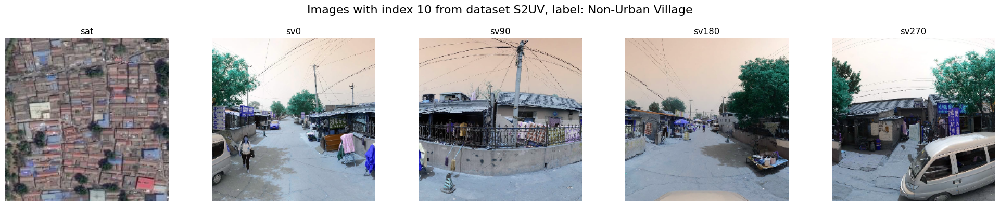

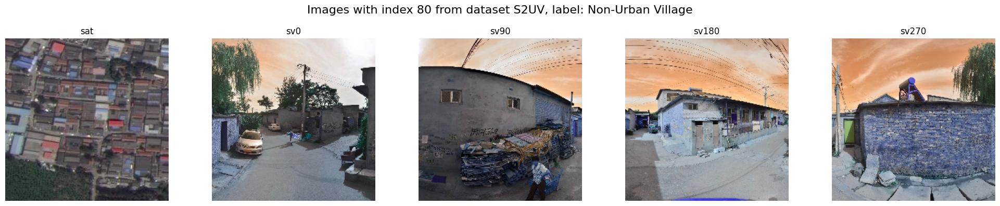

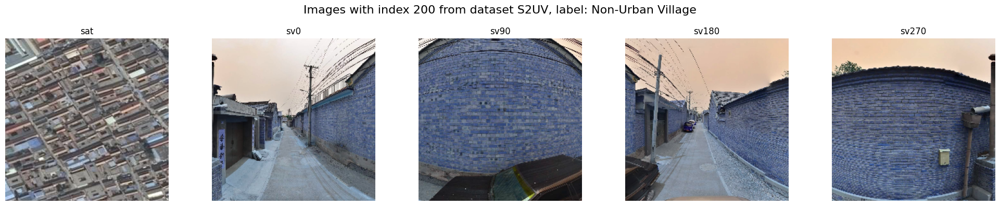

In [22]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

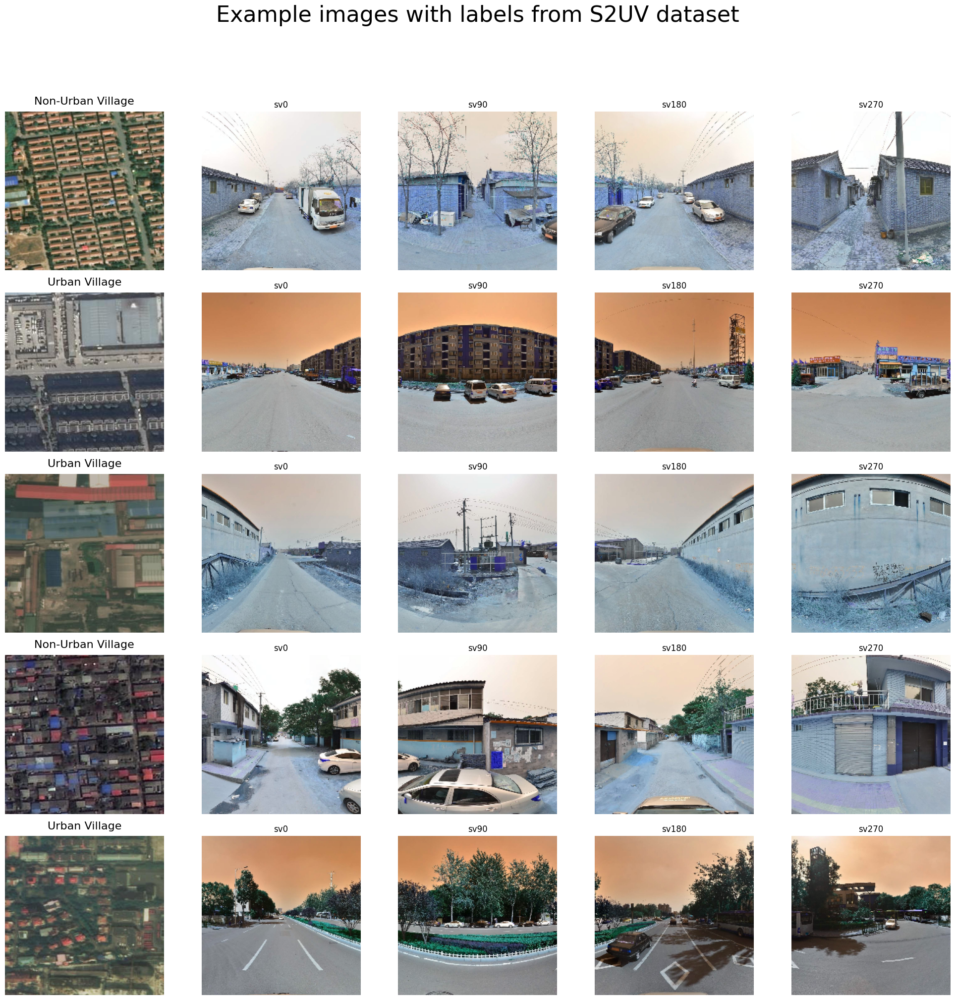

In [ ]:
fig4 = dataset.show_batch(5)

## Inspect the data

In [12]:
dataset.show_samples()

,Index,Label
0,0,Non-Urban Village
1,1,Non-Urban Village
2,2,Non-Urban Village
3,3,Non-Urban Village
4,4,Non-Urban Village
5,5,Non-Urban Village
6,6,Non-Urban Village
7,7,Non-Urban Village
8,8,Non-Urban Village
9,9,Non-Urban Village


In [13]:
dataset.data_distribution_table()

,Label,Count
0,Non-Urban Village,959
1,Urban Village,479


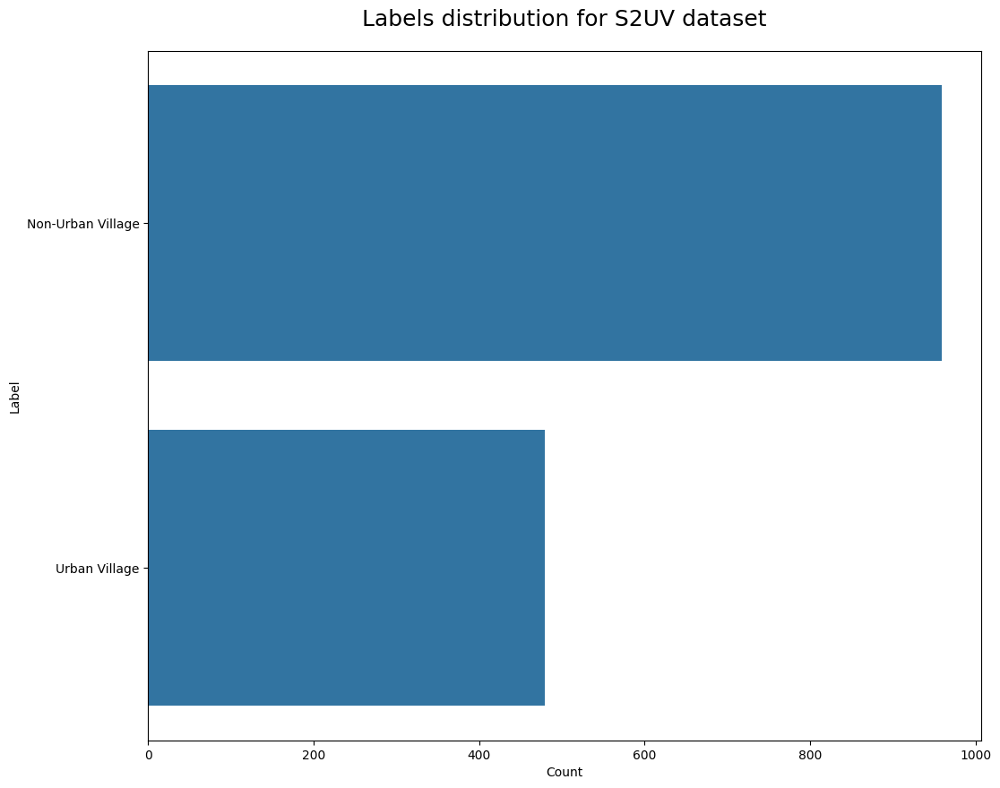

In [4]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/s2uv/train",
    "selection" : "0" 
}

train_dataset = S2UVDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/s2uv/val",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"],
    "selection":"0"
}

validation_dataset = S2UVDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(1438, 360)

## Setup and create the model for training

In [24]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/s2uv"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-08-26 11:43:14,538 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-08-26 11:43:14,711 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [52]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-07-08 13:09:14,150 INFO Starting training.
training: 100%|██████████| 45/45 [01:49<00:00,  2.43s/it]
2025-07-08 13:11:03,740 INFO epoch: 1, time: 109, loss:  0.35574
testing on train set: 100%|██████████| 45/45 [01:45<00:00,  2.35s/it]
2025-07-08 13:12:51,777 INFO Accuracy:0.8908205841446454, Precision Micro:0.8908205841446454, Precision Macro:0.8763497182855439, Precision Weighted:0.9172086336524186, Precision per Class:[0.75394322 0.99875622], Recall Micro:0.8908205841446454, Recall Macro:0.917621434993393, Recall Weighted:0.8908205841446455, Recall per Class:[0.99791232 0.83733055], F1_score Micro:0.8908205841446448, F1_score Macro:0.8849435256717006, F1_score Weighted:0.8936234889548181, F1_score per Class:[0.8589398  0.91094725]
testing on validation set: 100%|██████████| 12/12 [00:07<00:00,  1.54it/s]
2025-07-08 13:12:59,577 INFO Accuracy:0.8888888888888888, Precision Micro:0.8888888888888888, Precision Macro:0.8741070309562602, Precision Weighted:0.9144211889543383, Precisi

0.025578210319771907

## Test the model

In [33]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/s2uv/test",
    "selection" : "0",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = S2UVDataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/s2uv/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-08-26 11:46:03,626 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/s2uv/checkpoint.pth.tar
2025-08-26 11:46:03,816 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/s2uv/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 49/49 [00:02<00:00, 18.88it/s]


[{'Accuracy': 0.9689119170984456},
 {'Precision Micro': 0.9689119170984456,
  'Precision Macro': 0.9658588386998901,
  'Precision Weighted': 0.9688653052144982,
  'Precision per Class': array([0.95686275, 0.97485493])},
 {'Recall Micro': 0.9689119170984456,
  'Recall Macro': 0.9640285595557403,
  'Recall Weighted': 0.9689119170984457,
  'Recall per Class': array([0.94941634, 0.97864078])},
 {'F1_score Micro': 0.968911917098445,
  'F1_score Macro': 0.9649345930232553,
  'F1_score Weighted': 0.9688813222978667,
  'F1_score per Class': array([0.953125  , 0.97674419])}]

## Predictions

2025-08-26 12:01:58,316 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/s2uv/checkpoint.pth.tar
2025-08-26 12:01:58,510 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/s2uv/checkpoint.pth.tar at epoch 11


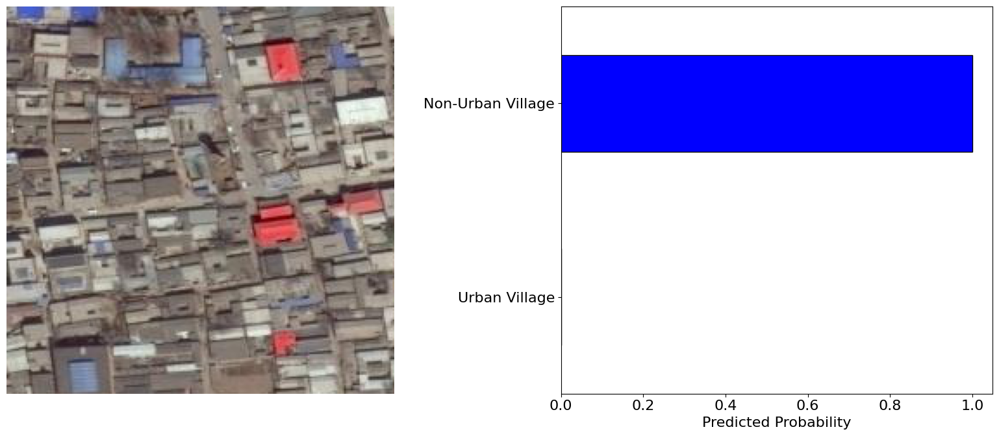

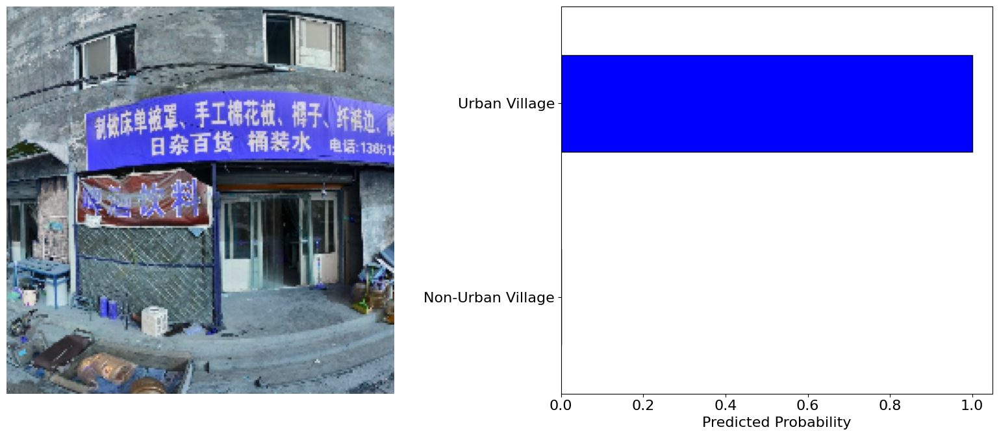

In [50]:
labels = ["Non-Urban Village", "Urban Village"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/s2uv/checkpoint.pth.tar"
model.load_model(model_path)

test_dir = "/home/dragik/data/FAIR_EO/s2uv/test/test_X.npy"
test_data = np.load(test_dir)

index = 0
sample = test_data[index]
image = sample[index]
fig = model.predict_image(image, labels, transform)

index = 2
sample = test_data[index]
image = sample[index]
fig = model.predict_image(image, labels, transform)